# B3: RoPE (rotary position embeddings)

Attention compares queries and keys with a dot product, which by itself knows nothing about *where* in the sequence a token is. RoPE injects position by **rotating** each query and key vector by an angle that grows with the position.

For TinyLlama `head_dim = 64`, so each head vector holds **32 pairs**. Hugging Face pairs dimension `i` with dimension `i + 32` (not neighbours). Pair `i` is rotated by `angle = position x inv_freq[i]` with `inv_freq[i] = 1 / 10000^(2i/64)`:

```
x_rot = x * cos + rotate_half(x) * sin          rotate_half([x1, x2]) = [-x2, x1]
```

**Why scores become relative:** a rotation by `m` followed by the transpose of a rotation by `n` is one rotation by `m - n`, so `<R_m q, R_n k> = q^T R_(n-m) k`. It depends only on the *difference* of positions.

Design points for our engine: positions are an explicit `(N,)` tensor (in a flattened batch every sequence restarts at 0); `cos`/`sin` are computed in FP32 and cast to the input dtype, like Hugging Face; it is applied to queries and keys, **not** values.

Code: `tinyserve/models/rope.py`. Tests: `tests/test_b3_rope.py`.

In [1]:
# Setup: clone or hard-reset the repo to GitHub, cd into it, put it on sys.path, install pytest.
import os, subprocess, sys

REPO_URL = "https://github.com/guptasameer112/tinyserve.git"
REPO_DIR = "/content/tinyserve"
if os.path.isdir(REPO_DIR):
    # Colab may hold untracked files (e.g. results written by a notebook) that clash with a pull.
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "reset", "--hard", "origin/main"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
print(subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout)

335035c B3: RoPE (HF convention, explicit positions), probe helpers, plot, tests, notebook



In [2]:
import importlib, json, math
import torch
import tinyserve.quiet, tinyserve.basics, tinyserve.models.rope, tinyserve.probe, tinyserve.plots
for module in (tinyserve.quiet, tinyserve.basics, tinyserve.models.rope, tinyserve.probe, tinyserve.plots):
    importlib.reload(module)  # picks up repo edits without restarting the kernel
from tinyserve.envinfo import collect_env
from tinyserve.models.rope import apply_rope, rope_cos_sin, rope_inv_freq

print(collect_env())

{'python': '3.13.16', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'git_sha': '335035c', 'gpu': 'Tesla T4', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'transformers': '5.21.0'}


## 1. By hand, with `head_dim = 4`
Two pairs: `(0, 2)` and `(1, 3)`, speeds `inv_freq = [1, 0.01]` radians per position. Put `x = [1, 0, 0, 0]` at position 1. Pair `(0, 2)` is `(1, 0)`, rotated by 1 radian: `(cos 1, sin 1) = (0.5403, 0.8415)`. So the result is `[0.5403, 0, 0.8415, 0]`.

In [3]:
x_small = torch.tensor([[[1.0, 0.0, 0.0, 0.0]]])  # (N=1, heads=1, head_dim=4)
cos_small, sin_small = rope_cos_sin(torch.tensor([1]), 4, 10000.0, torch.float32)
print("inv_freq:", rope_inv_freq(4, 10000.0, "cpu").tolist())
print("ours   :", apply_rope(x_small, cos_small, sin_small)[0, 0].tolist())
print("by hand:", [math.cos(1.0), 0.0, math.sin(1.0), 0.0])

inv_freq: [1.0, 0.009999999776482582]
ours   : [0.5403023362159729, 0.0, 0.8414709568023682, 0.0]
by hand: [0.5403023058681398, 0.0, 0.8414709848078965, 0.0]


## 2. The 32 rotation speeds
Pair 0 turns a full circle every ~6 positions (it resolves neighbours); the last pair turns so slowly that it barely moves across the whole 2048-token context. Fast pairs encode fine position, slow pairs coarse position.

pair  rad/position  wavelength (positions)   turned over 2048 positions (rad)
   0      1.000000                     6.3                           2048.000
   1      0.749894                     8.4                           1535.783
   2      0.562341                    11.2                           1151.675
   4      0.316228                    19.9                            647.634
   8      0.100000                    62.8                            204.800
  16      0.010000                   628.3                             20.480
  24      0.001000                  6283.2                              2.048
  31      0.000133                 47117.2                              0.273


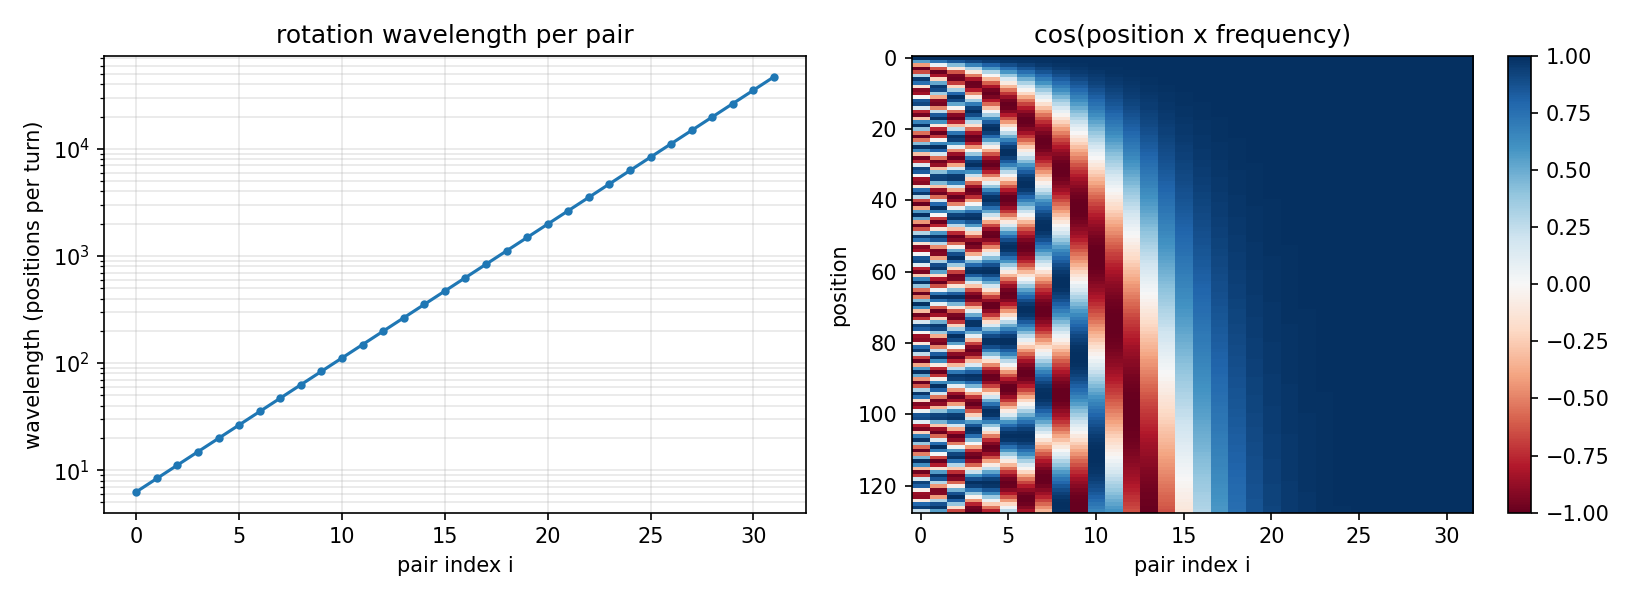

In [4]:
from IPython.display import Image, display
from tinyserve.plots import plot_rope

inv_freq = rope_inv_freq(64, 10000.0, "cpu")
print(f"{'pair':>4} {'rad/position':>13} {'wavelength (positions)':>23} {'turned over 2048 positions (rad)':>34}")
for pair in (0, 1, 2, 4, 8, 16, 24, 31):
    speed = inv_freq[pair].item()
    print(f"{pair:>4} {speed:13.6f} {2 * math.pi / speed:23.1f} {speed * 2048:34.3f}")
os.makedirs("results", exist_ok=True)
display(Image(plot_rope(inv_freq.tolist(), 128, "results/B3_rope.png")))

## 3. Scores depend only on the distance
Put the **same** query vector at all 64 positions and the **same** key vector at all 64 positions, rotate, and compute `S[m, n] = <R_m q, R_n k>`. If the claim is right, `S` is constant along every diagonal (`n - m` fixed).

In [5]:
from tinyserve.probe import relative_score_matrix, diagonal_spread

generator = torch.Generator().manual_seed(0)
query_vector, key_vector = torch.randn(64, generator=generator), torch.randn(64, generator=generator)
scores = relative_score_matrix(query_vector, key_vector, 64, 10000.0)
scale = query_vector.norm().item() * key_vector.norm().item()
print(f"|q||k| = {scale:.1f}; typical score size {scores.abs().mean().item():.2f}")
print(f"largest difference along any diagonal: {diagonal_spread(scores):.2e}")
print(f"offset 3 at (m=5, n=2)   : {scores[5, 2].item():.4f}")
print(f"offset 3 at (m=60, n=57) : {scores[60, 57].item():.4f}   <- same distance, same score")
print(f"offset 1 at (m=5, n=4)   : {scores[5, 4].item():.4f}   <- different distance, different score")

|q||k| = 69.2; typical score size 7.40
largest difference along any diagonal: 1.72e-05
offset 3 at (m=5, n=2)   : -8.8666
offset 3 at (m=60, n=57) : -8.8666   <- same distance, same score
offset 1 at (m=5, n=4)   : -12.4055   <- different distance, different score


## 4. Against the real model
We capture the real query and key projections of layers 0, 10 and 21 for a prompt (the outputs of `q_proj` and `k_proj`, shapes `(N, 32, 64)` and `(N, 4, 64)` after reshaping), rotate them with our code and with the Hugging Face rotary embedding, and compare. We try ordinary positions `0..N-1` and a *packed* pattern where two sequences restart at 0. Our recipe matches Hugging Face's, so we expect exact equality in FP16.

In [6]:
from tinyserve.basics import load_model, encode
from tinyserve.probe import capture_module_io, compare_rope

tokenizer, model = load_model(device="cuda", dtype=torch.float16)
config = model.config
head_dim = config.hidden_size // config.num_attention_heads
prompt_ids = encode(tokenizer, "The capital of France is", "cuda")
num_tokens = len(prompt_ids)
projection_outputs = {name: output for name, _, output in capture_module_io(model, prompt_ids, torch.nn.Linear)}

position_patterns = {"0..N-1": torch.arange(num_tokens, device="cuda"),
                     "packed (two sequences)": torch.tensor([0, 1, 2, 0, 1, 2], device="cuda")}
rope_rows = []
for layer in (0, 10, 21):
    q = projection_outputs[f"model.layers.{layer}.self_attn.q_proj"][0].reshape(num_tokens, config.num_attention_heads, head_dim)
    k = projection_outputs[f"model.layers.{layer}.self_attn.k_proj"][0].reshape(num_tokens, config.num_key_value_heads, head_dim)
    for pattern_name, positions in position_patterns.items():
        result = compare_rope(model, q, k, positions)
        result.update({"layer": layer, "positions": pattern_name})
        rope_rows.append(result)
        print(f"layer {layer:>2} {pattern_name:<24} cos/sin equal {result['cos_sin_equal']}  q equal {result['q_equal']}  k equal {result['k_equal']}  "
              f"max |diff| q {result['q_max_abs_diff']:.1e} k {result['k_max_abs_diff']:.1e}")
print("q shape:", tuple(q.shape), " k shape:", tuple(k.shape))

layer  0 0..N-1                   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
layer  0 packed (two sequences)   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
layer 10 0..N-1                   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
layer 10 packed (two sequences)   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
layer 21 0..N-1                   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
layer 21 packed (two sequences)   cos/sin equal True  q equal True  k equal True  max |diff| q 0.0e+00 k 0.0e+00
q shape: (6, 32, 64)  k shape: (6, 4, 64)


## 5. Save results and run the tests

In [7]:
from tinyserve.envinfo import save_result

saved_path = save_result("B3_rope", {
    "head_dim": head_dim,
    "theta": 10000.0,
    "inv_freq_pair0": inv_freq[0].item(),
    "inv_freq_pair31": inv_freq[31].item(),
    "wavelength_pair0": 2 * math.pi / inv_freq[0].item(),
    "wavelength_pair31": 2 * math.pi / inv_freq[31].item(),
    "diagonal_spread_fp32": diagonal_spread(scores),
    "score_scale_q_norm_k_norm": scale,
    "real_model_comparison": rope_rows,
})
print(saved_path)

/content/tinyserve/results/B3_rope.json


In [8]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_b3_rope.py", "-v"], capture_output=True, text=True)
print(result.stdout[-5000:], result.stderr[-1000:])

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/tinyserve
configfile: pyproject.toml
plugins: typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collecting ... collected 16 items

tests/test_b3_rope.py::test_inv_freq_values_for_head_dim_64 PASSED       [  6%]
tests/test_b3_rope.py::test_rotate_half_swaps_halves_with_a_sign PASSED  [ 12%]
tests/test_b3_rope.py::test_hand_computed_example PASSED                 [ 18%]
tests/test_b3_rope.py::test_position_zero_is_identity PASSED             [ 25%]
tests/test_b3_rope.py::test_rotation_preserves_vector_length PASSED      [ 31%]
tests/test_b3_rope.py::test_rows_depend_only_on_their_own_position PASSED [ 37%]
tests/test_b3_rope.py::test_score_depends_only_on_relative_position PASSED [ 43%]
tests/test_b3_rope.py::test_fp32_matches_huggingface[positions0] PASSED  [ 50%]
te

In [11]:
# Print the full results file so it can be copied into the repo from the saved notebook.
print(open(saved_path).read())

{
  "name": "B3_rope",
  "timestamp_utc": "2026-10-31T04:13:12Z",
  "env": {
    "python": "3.13.16",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "git_sha": "335035c",
    "gpu": "Tesla T4",
    "torch": "2.11.0+cu130",
    "cuda": "13.0",
    "transformers": "5.21.0"
  },
  "data": {
    "head_dim": 64,
    "theta": 10000.0,
    "inv_freq_pair0": 1.0,
    "inv_freq_pair31": 0.0001333521504420787,
    "wavelength_pair0": 6.283185307179586,
    "wavelength_pair31": 47117.24022709838,
    "diagonal_spread_fp32": 1.71661376953125e-05,
    "score_scale_q_norm_k_norm": 69.24680683511542,
    "real_model_comparison": [
      {
        "cos_sin_equal": true,
        "q_equal": true,
        "k_equal": true,
        "q_max_abs_diff": 0.0,
        "k_max_abs_diff": 0.0,
        "layer": 0,
        "positions": "0..N-1"
      },
      {
        "cos_sin_equal": true,
        "q_equal": true,
        "k_equal": true,
        "q_max_abs_diff": 0.0,
        "k_max_abs_diff": 0.0,
  

In [12]:
from pathlib import Path
print(Path("/content/tinyserve/results/B3_rope.json").read_text())

{
  "name": "B3_rope",
  "timestamp_utc": "2026-10-31T04:13:12Z",
  "env": {
    "python": "3.13.16",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "git_sha": "335035c",
    "gpu": "Tesla T4",
    "torch": "2.11.0+cu130",
    "cuda": "13.0",
    "transformers": "5.21.0"
  },
  "data": {
    "head_dim": 64,
    "theta": 10000.0,
    "inv_freq_pair0": 1.0,
    "inv_freq_pair31": 0.0001333521504420787,
    "wavelength_pair0": 6.283185307179586,
    "wavelength_pair31": 47117.24022709838,
    "diagonal_spread_fp32": 1.71661376953125e-05,
    "score_scale_q_norm_k_norm": 69.24680683511542,
    "real_model_comparison": [
      {
        "cos_sin_equal": true,
        "q_equal": true,
        "k_equal": true,
        "q_max_abs_diff": 0.0,
        "k_max_abs_diff": 0.0,
        "layer": 0,
        "positions": "0..N-1"
      },
      {
        "cos_sin_equal": true,
        "q_equal": true,
        "k_equal": true,
        "q_max_abs_diff": 0.0,
        "k_max_abs_diff": 0.0,
  

In [10]:
# Free the GPU for the next notebook: every kernel on this Colab server keeps its own copy of the model.
import gc
import sys
import torch
for name in ("model", "params", "projection_outputs", "q", "k"):
    globals().pop(name, None)
for name in ("last_traceback", "last_value", "last_type", "last_exc"):  # an old error can keep tensors alive
    if hasattr(sys, name):
        setattr(sys, name, None)
gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory still held by this kernel: {torch.cuda.memory_allocated() / 2**20:.0f} MiB")

GPU memory still held by this kernel: 8 MiB
